# LangChain 멀티모달 RAG 실습 — FashionRAG
### CLIP 이미지 검색 + GPT 비전 모델로 만드는 패션 스타일링 어시스턴트

| 항목 | 내용 |
|---|---|
| 준비물 | OpenAI API 키, 디스크 여유 약 3GB, 인터넷 연결 |
| 결과물 | 한국어로 질문하면 비슷한 패션 사진을 찾아 보여주고 스타일링 조언을 해주는 챗봇 |

**사용법**: 위에서부터 셀을 하나씩 `Shift + Enter` 로 실행하세요. 코드의 주석(`#`)을 꼭 읽으면서 진행하세요.
`✏️ 실습` 셀의 `TODO` 부분은 직접 채워 넣는 문제입니다.


## 학습 목표

1. **멀티모달 RAG** 의 구조(Retrieval → Augmentation → Generation)를 설명할 수 있다.
2. **CLIP** 이 텍스트와 이미지를 같은 벡터 공간에 놓는 원리를 이해하고, 텍스트로 이미지를 검색할 수 있다.
3. **Chroma 벡터 DB** 에 이미지를 저장(`add`)하고 검색(`query`)할 수 있다.
4. **LangChain LCEL**(`프롬프트 | 모델 | 파서`)로 번역 체인과 비전 체인을 만들 수 있다.
5. 이미지를 **base64 data URL** 로 변환해 GPT 비전 모델에 전달할 수 있다. 
  
    


> RAG의 정의:  
> LLM은 학습하지 않은 정보를 알 수 없기 때문에 질문과 관련된 자료를 검색해서(Retrieval), 프롬프트에 붙여넣고(Argumentation) 그 자료를 근거로 답하게(Generation)하는 방식  
> 
> 멀티모달 RAG:  
> 모달리티(Modality)란 데이터의 종류(텍스트, 이미지, 음성, 영상....)를 뜻한다.  
> 일만 RAG가 텍스트 문서만 검색한다면, 멀티모달RAG는 이미지, 음성 등.. 검색하고 이미지를 볼 수 있는 LLM(비전모델)에게 전달하여 답하게 하는 방식


## 목차

| 파트 | 내용 | 셀 |
|---|---|---|
| 0 | 전체 그림: 멀티모달 RAG 란? | 개념 |
| 1 | 환경 준비 (설치·임포트·API 키·설정값) | [환경]~[4] |
| 2 | 데이터 준비: Fashionpedia 스트리밍 | [5]~[7] |
| 3 | 임베딩 & 벡터 DB: CLIP + Chroma | [8]~[11] |
| 4 | LangChain 체인: 번역 체인 / 비전 체인 | [12]~[13] |
| 5 | 전체 파이프라인 & 대화형 모드 | [14]~[16] |
| 6 | 실습 문제 · 퀴즈 · 정리 | 실습 1~4 |


---
# Part 0. 전체 그림: 멀티모달 RAG

### RAG(Retrieval-Augmented Generation) 복습
LLM 은 학습하지 않은 정보(우리 회사 상품, 최신 데이터 등)를 모릅니다. 그래서 **질문과 관련된 자료를 먼저 찾아서(Retrieval)**, **프롬프트에 붙여 넣고(Augmentation)**, **그 자료를 근거로 답하게(Generation)** 하는 방식이 RAG 입니다.

### 멀티모달(Multimodal) RAG
'모달리티(modality)'는 데이터의 종류(텍스트, 이미지, 음성 …)를 뜻합니다.
일반 RAG 가 **텍스트 문서**를 검색한다면, 멀티모달 RAG 는 **이미지**를 검색하고 **이미지를 볼 수 있는 LLM(비전 모델)** 에게 전달합니다.

### 오늘 만들 FashionRAG 의 흐름

```
 사용자(한국어)  "가을 트렌치코트 스타일링 알려줘"
        │
        ▼  ① 번역 체인 (gpt-4o-mini)           ← LangChain LCEL
 "Trench coat styling for autumn"
        │
        ▼  ② CLIP 텍스트 임베딩 → Chroma 유사도 검색   ← Retrieval
 [image_0123.jpg, image_0456.jpg]   (가장 비슷한 사진 2장)
        │
        ▼  ③ 이미지 → base64 data URL, 질문과 함께 프롬프트 구성  ← Augmentation
        │
        ▼  ④ 비전 체인 (gpt-4o-mini, 이미지 이해)            ← Generation
 "In the first image, the beige trench coat ..."
        │
        ▼  ⑤ 번역 체인
 사용자에게 한국어 답변 + 검색된 사진 출력
```

### 사전 준비 단계 (최초 1회)
```
 Fashionpedia 데이터셋 ──(500장 저장)──▶ fashion_dataset/ 폴더
                                          │  CLIP 이미지 임베딩
                                          ▼
                                   Chroma 벡터 DB (img_vdb/)
```


---
# Part 1. 환경 준비

### 핵심 라이브러리 한눈에 보기
| 라이브러리 | 역할 | 오늘 사용하는 기능 |
|---|---|---|
| **datasets** | Hugging Face 데이터셋 로드 | `load_dataset(..., streaming=True)` |
| **open_clip / torch** | CLIP 모델 실행 | Chroma 의 `OpenCLIPEmbeddingFunction` 내부에서 사용 |
| **chromadb** | 벡터 DB | `PersistentClient`, `add`, `query` |
| **langchain-core** | LLM 앱 구성요소 | `ChatPromptTemplate`, `StrOutputParser`, `|` |
| **langchain-openai** | OpenAI 연결 | `ChatOpenAI` |


In [4]:
# ============================================================
# [환경 준비] 필수 패키지 설치  (최초 1회만 실행)
# ============================================================
# %pip  : '지금 이 노트북 커널'의 파이썬 환경에 패키지를 설치하는 매직 명령어
#         (!pip 는 다른 파이썬 환경에 설치될 수 있으므로 %pip 를 권장)
# -q    : 설치 로그를 간단히(quiet) 출력
#
# 패키지별 역할
#   chromadb         : 벡터 데이터베이스 (이미지 임베딩 저장/검색)
#   open-clip-torch  : CLIP 모델 (텍스트·이미지를 같은 벡터 공간으로 임베딩)
#                      -> PyTorch(torch)가 함께 설치되어 수 분 걸릴 수 있음
#   pillow           : 이미지 열기/저장 (PIL)
#   datasets         : Hugging Face 데이터셋 다운로드
#   langchain-core   : 프롬프트 템플릿, 출력 파서, LCEL 체인(|) 등 핵심 기능
#   langchain-openai : LangChain 에서 OpenAI 모델(ChatOpenAI) 사용
#   python-dotenv    : .env 파일의 환경변수(API 키) 로드
#
# 설치 후 "Restart Kernel"이 필요하다는 메시지가 나오면 커널을 재시작한 뒤
# 이 셀은 건너뛰고 다음 셀부터 실행하세요.

%pip -q install chromadb open-clip-torch pillow datasets langchain-openai langchain-core python-dotenv

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [5]:
# ============================================================
# [1] 라이브러리 임포트
# ============================================================

# --- 파이썬 표준 라이브러리 ---
# 파일/폴더 경로 조작, 환경변수 읽기·쓰기
import os

# 이미지(바이너리) -> 텍스트(base64 문자열) 변환
import base64

# API 키를 화면에 노출하지 않고 입력받기
from getpass import getpass

# --- 환경변수 ---
# .env 파일 내용을 os.environ 으로 불러옴
from dotenv import load_dotenv
# --- 벡터 데이터베이스 (Chroma) ---
import chromadb

# OpenCLIPEmbeddingFunction : 텍스트/이미지를 CLIP 벡터로 바꿔주는 '임베딩 함수'
from chromadb.utils.embedding_functions import OpenCLIPEmbeddingFunction

# ImageLoader : DB에 저장된 이미지 경로(URI)를 실제 이미지 배열로 읽어오는 '데이터 로더'
from chromadb.utils.data_loaders import ImageLoader

# --- 데이터셋 ---
# Hugging Face Hub 데이터셋 로더
from datasets import load_dataset

# --- LangChain ---
# OpenAI 채팅 모델 래퍼
from langchain_openai import ChatOpenAI
# 대화형 프롬프트 템플릿
from langchain_core.prompts import ChatPromptTemplate
# 모델 응답 -> 순수 문자열
from langchain_core.output_parsers import StrOutputParser

# --- 이미지 처리 & 노트북 출력 ---
# 이미지 열기/리사이즈/합치기
from PIL import Image
# 노트북에 이미지·마크다운 예쁘게 출력
from IPython.display import display, Markdown
print("라이브러리 임포트 완료")

라이브러리 임포트 완료


In [6]:
# 나는 됐는데
%pip install -q ipywidgets

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [7]:
# ============================================================
# [2] OpenAI API 키 설정
# ============================================================
# 

load_dotenv()                                   # .env 파일을 찾아 환경변수로 등록
OPENAI_API_KEY = os.getenv("OPENAI_API_KEY")    # 환경변수에서 키 읽기 (없으면 None)

if not OPENAI_API_KEY:
    # .env 도 환경변수도 없으면 직접 입력받음 (입력 내용은 화면에 표시되지 않음)
    OPENAI_API_KEY = getpass("OpenAI API 키를 입력하세요 (sk-...): ").strip()

if not OPENAI_API_KEY:
    # 그래도 비어 있으면 더 진행할 수 없으므로 명확한 에러를 발생시킴
    raise ValueError("OPENAI_API_KEY 가 설정되지 않았습니다. .env 파일 또는 입력으로 설정하세요.")

# ChatOpenAI 는 환경변수 OPENAI_API_KEY 를 자동으로 읽어 사용함
os.environ["OPENAI_API_KEY"] = OPENAI_API_KEY

# 키 전체를 출력하면 보안상 위험하므로 앞 6자리만 확인용으로 출력
print("API 키 설정 완료:", OPENAI_API_KEY[:6] + "...")

API 키 설정 완료: sk-pro...


### 설정값을 한 곳에 모으는 이유
경로·모델명·개수 같은 값이 코드 곳곳에 흩어져 있으면 바꾸기 어렵습니다. **맨 위 설정 셀만 고치면** 전체 동작이 바뀌도록 만드는 것이 좋습니다.


In [8]:
# ============================================================
# [3] 실습 설정값 (한 곳에서 관리)
# ============================================================
# 원본 스크립트의 os.path.abspath(__file__) 는 .py 파일에서만 동작합니다.
# 주피터 노트북에는 __file__ 변수가 없으므로(NameError) 현재 작업 폴더를 기준으로 합니다.
BASE_DIR = os.getcwd()

# 이미지를 저장할 폴더
DATASET_FOLDER    =   os.path.join(BASE_DIR, "fashion_dataset")

# Chroma DB 저장 폴더
VDB_PATH    =    os.path.join(BASE_DIR, "img_vdb")

# Chroma 컬렉션(=테이블) [테이블 이름을 지정할때는:이름 (3자 이상, 영문/숫자/._-)만 가능하다]
COLLECTION_NAME    =    "fashion_images"

NUM_IMAGES = 100    # 데이터셋에서 가져올 이미지 수 (수업 시간이 부족하면 100 정도로 줄이세요)
N_RESULTS  = 2      # 질문 하나당 검색할 이미지 수 (비전 프롬프트에 이미지 2장이 들어감)

# 사용할 OpenAI 모델 이름 
TRANSLATION_MODEL = "gpt-4o-mini"                # 한<->영 번역용 
VISION_MODEL      = "gpt-4o-mini"                # 이미지를 이해하는 비전 모델 

# 이미지로 인식할 확장자 (원본은 .png 만 처리) 
IMAGE_EXTS = (".jpg", ".jpeg", ".png")

print("작업 폴더   :", BASE_DIR)
print("이미지 폴더 :", DATASET_FOLDER)
print("벡터DB 폴더 :", VDB_PATH)

작업 폴더   : c:\workspaces\part2\fashionRAG-assistant
이미지 폴더 : c:\workspaces\part2\fashionRAG-assistant\fashion_dataset
벡터DB 폴더 : c:\workspaces\part2\fashionRAG-assistant\img_vdb


In [9]:
# type은 무엇일까
print(os.path.isdir(".venv"))
print()
print( os.listdir(".venv"))
print( sorted(os.listdir(".venv")))
print(type(os.listdir(".venv")))
print(type(sorted(os.listdir(".venv"))))

True

['etc', 'Include', 'Lib', 'pyvenv.cfg', 'Scripts', 'share']
['Include', 'Lib', 'Scripts', 'etc', 'pyvenv.cfg', 'share']
<class 'list'>
<class 'list'>


In [10]:
# ============================================================
# [4] 보조 함수(helper_function): 이미지 파일 목록 / 썸네일 그리드 출력 / MIME 추정
# ============================================================

def list_image_files(folder):
    """folder 안의 이미지 파일 이름을 '정렬된 리스트'로 반환합니다.

    - 폴더가 없으면 빈 리스트를 반환합니다.
    - 파일명을 image_0001.jpg 처럼 0으로 채워(zero-padding) 저장하기 때문에
      문자열 정렬 결과가 곧 숫자 순서와 같아집니다.
    """
    if not os.path.isdir(folder):
        return []
    return sorted(
        f for f in os.listdir(folder)       # 폴더 안의 모든 파일 이름 중
        if f.lower().endswith(IMAGE_EXTS)    # 이미지 확장자로 끝나는 것만 선택
    )
  
# ============================================================

def show_image_grid(paths, captions=None, thumb=220):
    """여러 이미지 경로를 받아 가로로 이어 붙인 '썸네일 한 장'으로 노트북에 출력합니다.
    (matplotlib 없이 PIL 만으로 구현)"""
    
    # 가로로 나란히 붙일 빈 캔버스 생성 (흰 배경, 이미지 사이 10px 여백)
    thumbs =[]
    for p in paths:
        img = Image.open(p).convert("RGB")
        img.thumbnail((thumb, thumb))
        thumbs.append(img)
    if not thumbs:
        print("표시할 이미지가 없습니다.")
        return
    # 가로로 나란히 붙일 빈 캔버스(도화지) 생성. 여기에 이미지 출력하게 하겠음.(흰색 배경, 이미지 사이 10px 여백)
    gap = 10
    width = sum(t.width for t in thumbs) + gap * (len(thumbs)-1)
    height = max(t.height for t in thumbs)
    canvas = Image.new('RGB',(width,height), "white")

    x = 0
    for t in thumbs:
        canvas.paste(t,(x,0))
        x += t.width +gap
    display(canvas)
    if captions:
        print("|".join(captions)) # 노트북에 이미지 출력

# ============================================================

def guess_mime(path):
    """파일 확장자로 이미지 MIME 타입을 추정합니다. (data URL 만들 때 사용)"""
    ext = os.path.splitext(path)[1].lower()
    return "image/png" if ext == ".png" else "image/jpeg"

print("보조 함수 정의 완료")

보조 함수 정의 완료


> **나의 메모** : (이 칸을 더블클릭해서 수업 중 알게 된 점을 적어 보세요)
>
> - os.listdir()을 통해서 디렉토리의 요소들을 리스트로 받을 수 있다.
> - os.getcwd()를 통해서 작업 최상위 root 위치를 찾을 수 있다.
> - PIL에서 제공하는 thumbnail 매서드를 이용해 썸네일을 출력할 수 있다.

---
# Part 2. 데이터 준비 — Fashionpedia

### Fashionpedia 데이터셋
- 일상·셀럽 행사 패션 사진에 **27개 의류 카테고리, 19개 의류 부위, 294개 세부 속성**을 라벨링한 데이터셋 (CC BY 4.0)
- Hugging Face ID: `detection-datasets/fashionpedia` — train 45,623장 / val 1,158장
- 원래는 객체 탐지(Object Detection)용이지만, 오늘은 **사진만** 꺼내서 검색 대상으로 사용합니다.

### 스트리밍(streaming) 모드
| 방식 | 동작 | 500장 쓰려면 |
|---|---|---|
| 일반 `load_dataset(id)` | 전체 파일을 디스크에 받은 뒤 로드 | **약 3.5GB 전부** 다운로드 |
| `load_dataset(id, streaming=True)` | 필요한 만큼만 순서대로 읽어 옴 | 500장 분량만 다운로드 |

`streaming=True` 이면 결과가 `IterableDataset` 이 되어 인덱스 접근(`ds[0]`) 대신 **반복(for)·`.take(n)`** 으로 사용합니다.


빈칸문제로 시험에 나올 것.

In [11]:
# ============================================================
# [5] 데이터셋 불러오기 & 이미지 저장 함수
# ============================================================

def setup_dataset():
    """Fashionpedia 데이터셋을 '스트리밍' 모드로 연결합니다.

    """
    dataset = load_dataset(
        "detection-datasets/fashionpedia",
        split="train",
        streaming =True,
    )
    os.makedirs(DATASET_FOLDER, exist_ok=True)
    return dataset

# ============================================================

def save_images(dataset, dataset_folder=DATASET_FOLDER, num_images=NUM_IMAGES):   # python에서 파일 처리 하는 방법가지 한번에 배우게 됨.
    """스트리밍 데이터셋에서 앞쪽 num_images 장을 JPEG 파일로 저장합니다.

    - dataset.take(n)  : 스트림에서 앞의 n개 샘플만 꺼냄
    - example["image"] : 데이터셋의 'image' 컬럼 -> PIL.Image 객체로 자동 디코딩됨
    - 파일명 image_0001.jpg : 0 패딩으로 정렬 순서 == 번호 순서 보장
      (원본의 image_1.png, image_10.png, image_100.png ... 사전식 정렬 문제 해결)
    - JPEG 저장 : 원본 사진이 JPEG 이므로 PNG 보다 용량이 훨씬 작고,
      이후 OpenAI 로 base64 전송할 때 데이터량도 줄어듦
    """
    saved = 0 # 저장된 파일을 count할 변수
    for i, example in enumerate(dataset.take(num_images)):  #dataset은 streaming 통로가 된다.
        image = example["image"]
        file_path = os.path.join(dataset_folder,f"image_{i+1:04d}.jpg")
        image.convert("RGB").save(file_path,format="JPEG", quality=90)
        saved += 1

        if saved % 50 ==0:
            print(f"...{saved}/{num_images}장 저장")
    print(f"{saved}장의 이미지를 '{dataset_folder}'에 저장완료")
    return saved    

print("데이터셋 함수 정의 완료")

데이터셋 함수 정의 완료


In [12]:
# ============================================================
# [6] 데이터셋 준비 실행 (이미 저장돼 있으면 건너뜀)
# ============================================================
# 이미 저장된 이미지 목록
existing = list_image_files(DATASET_FOLDER)
if len(existing) >= NUM_IMAGES:
    print(f"이미지 {len(existing)}장이 있습니다. 다운로드를 건너뜁니다.")
else:
    print(f"Fashinpedia 데이터 셋에서 이미지를 다운로들 합니다.")
    dataset = setup_dataset()
    save_images(dataset, DATASET_FOLDER, NUM_IMAGES)

image_files = list_image_files(DATASET_FOLDER)

print("저장된 이미지 수:", len(image_files))
print("파일명 예시   :", image_files[:3])

이미지 100장이 있습니다. 다운로드를 건너뜁니다.
저장된 이미지 수: 100
파일명 예시   : ['image_0001.jpg', 'image_0002.jpg', 'image_0003.jpg']


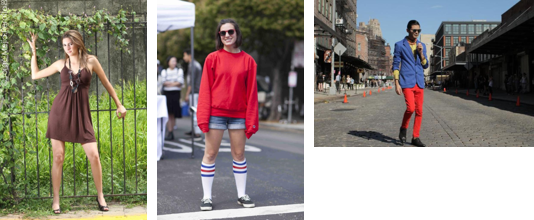

image_0001.jpg|image_0002.jpg|image_0003.jpg


In [13]:
# ============================================================
# [7] 저장된 이미지 미리보기 (데이터가 어떻게 생겼는지 눈으로 확인)
# ============================================================
sample_path = [os.path.join(DATASET_FOLDER,f) for f in image_files[:3]]
show_image_grid(sample_path, captions = image_files[:3])

> **나의 메모** : (이 칸을 더블클릭해서 수업 중 알게 된 점을 적어 보세요)
>
> - 파일을 처리하는 방법과 폴더를 처리하는 방법을 배움.
> - 위치정보를 찾아오는 것과
> - 허깅페이스에서 내가 정한 num_image만큼 가지고 오겠다. streaming을 이용해 실시간으로. DATASET_folder에 저장해두겠다.

---
# Part 3. 임베딩 & 벡터 DB — CLIP + Chroma

### 임베딩(Embedding)이란?
데이터를 **의미를 담은 숫자 벡터**로 바꾼 것입니다. 의미가 비슷하면 벡터도 가까워집니다.

### CLIP (Contrastive Language-Image Pre-training)
- OpenAI 가 2021년에 발표한 모델 구조이며, 오늘 쓰는 것은 LAION 이 공개 데이터(LAION-2B, 약 20억 쌍)로 학습한 **OpenCLIP ViT-B-32** 입니다.
- **이미지 인코더**와 **텍스트 인코더** 두 개로 구성되며, 둘 다 **512차원** 벡터를 출력합니다.
- 학습 방법(대조 학습): "사진–설명" 짝은 벡터를 **가깝게**, 짝이 아닌 것은 **멀게** 만들도록 학습.
- 결과적으로 **텍스트와 이미지가 같은 공간**에 놓여, `"a red dress"` 텍스트 벡터 근처에 빨간 드레스 사진 벡터들이 모입니다.

```
           512차원 공간 (개념도)
   "a red dress" ●──┐
                    ├─ 가까움 →  📷 빨간 드레스 사진
                    └─ 가까움 →  📷 와인색 원피스 사진
   "a black jacket" ●────────→  📷 검정 재킷 사진   (빨간 드레스와는 멀다)
```

### 벡터 DB — Chroma
| 개념 | 설명 | 코드 |
|---|---|---|
| Client | DB 연결. `PersistentClient` 는 디스크에 저장 | `chromadb.PersistentClient(path=...)` |
| Collection | 테이블 같은 단위 | `get_or_create_collection(name=...)` |
| Embedding Function | 데이터 → 벡터 자동 변환 | `OpenCLIPEmbeddingFunction()` |
| Data Loader | URI(경로) → 실제 데이터 로딩 | `ImageLoader()` |
| add / query | 저장 / 유사도 검색 | `add(ids, uris)`, `query(query_texts, n_results)` |

**`add(uris=...)` 내부 동작**: 경로 → `ImageLoader` 가 이미지 읽기 → CLIP 이미지 인코더 → 벡터 저장
**`query(query_texts=...)` 내부 동작**: 텍스트 → CLIP 텍스트 인코더 → 저장된 이미지 벡터들과 거리 계산 → 가까운 순 반환

### 거리(distance) 읽는 법
- Chroma 기본 거리 함수는 **제곱 유클리드 거리(L2²)** 입니다. **작을수록 비슷**합니다.
- CLIP 벡터는 길이 1로 정규화되어 있어 `L2² = 2 − 2 × 코사인유사도` 관계가 성립 → 순위는 코사인 유사도와 동일합니다.


새로 추가된 이미지만 임베딩 진행하겠다는 비즈니스 로직. 중요함.

In [14]:
# ============================================================
# [8] Chroma 벡터 DB 설정 & 이미지 등록 함수
# ============================================================

def setup_chroma_db(vdb_path=VDB_PATH, collection_name=COLLECTION_NAME):
    """CLIP 임베딩 함수를 연결한 Chroma 컬렉션을 생성(또는 기존 것 로드)해 반환합니다."""
    # PersistentClient : 디스크(vdb_path)에 DB를 저장 -> 노트북을 껐다 켜도 유지
    #                    (chromadb.Client() 는 메모리 전용이라 종료 시 사라짐)
    chroma_client = chromadb.PersistentClient(vdb_path)

    # ImageLoader : add/query 때 넘긴 uris(파일 경로)를 실제 이미지(numpy 배열)로 읽어줌
    image_loader = ImageLoader()

    # OpenCLIPEmbeddingFunction : 기본값 ViT-B-32 모델 + laion2b_s34b_b79k 가중치
    #   - 첫 실행 시 Hugging Face 에서 약 600MB 가중치를 다운로드 (이후 캐시 사용)
    #   - 텍스트와 이미지를 '같은 512차원 공간'의 벡터로 변환 -> 텍스트로 이미지 검색 가능
    clip = OpenCLIPEmbeddingFunction()

    # get_or_create_collection : 같은 이름의 컬렉션이 있으면 가져오고, 없으면 새로 만듦
    image_vdb = chroma_client.get_or_create_collection(
        name = collection_name,
        embedding_function = clip,
        data_loader = image_loader, # 텍스트로 이미지 검색이 가능하도록 하겠다.
    )
    return image_vdb
    

# ============================================================

# 경로를 지정 => ImageLoader를 통해 => 이미지배열 => CLIP이미지인코더 => 512차원 벡터로 변환
# => img_vdb에 파일형태로 저장한다.
# 위 순서를 기억하는 것이 중요하다.

# ============================================================

def add_images_to_db(image_vdb, dataset_folder=DATASET_FOLDER, batch_size=50):
    """폴더의 이미지를 벡터 DB에 등록합니다. 
       이미 등록된 이미지는 건너뜁니다.
    """
    files = list_image_files(dataset_folder)
        
    # 'image_0001.jpg' -> 'image_0001'
    ids = [os.path.splitext(f)[0] for f in files]
    # 이미지 전체 경로
    uris = [os.path.join(dataset_folder, f) for f in files] # 이미지 전체 경로
    
    # include=[] : 벡터·문서 등은 빼고 id 만 가볍게 조회
    existing_ids = set(image_vdb.get(include=[])["ids"])
    
    # 키와 위치값을 이용해 zip한 뒤 새로운 목록을 만든다.
    new_items = [(i,u) for i, u in zip(ids,uris) if i not in existing_ids]
    # 
    if not new_items:
        print(f"추가할 새 이미지가 없습니다. (현재DB 이미지 수: {image_vdb.count()})")
        return
    
    print(f"새 이미지 {len(new_items)}장을 임베딩하여 등록합니다. (CPU 기준 수 분 소요)")

    # batch_size 장씩 나눠서 추가 -> 진행 상황 확인 + 메모리 사용량 제한
    for start in range(0, len(new_items), batch_size):
        batch = new_items[start:start + batch_size]
        image_vdb.add(
            ids = [i for i, _ in batch],
            uris = [u for _, u in batch],
        )
        print(f"...{min(start + batch_size, len(new_items))}/{len(new_items)} 등록")
    

    
    print(f"이미지가 벡터 데이터베이스에 추가되었습니다. (총 {image_vdb.count()}장)")

print("벡터 DB 함수 정의 완료")

벡터 DB 함수 정의 완료


In [15]:
# 코드에 대한 타입 확인
print([os.path.splitext(f)[0] for f in list_image_files(DATASET_FOLDER)])
print(type([os.path.splitext(f)[0] for f in list_image_files(DATASET_FOLDER)]))
print()
print(type(list_image_files(DATASET_FOLDER)))
print(list_image_files(DATASET_FOLDER))
print(os.path.splitext(list_image_files(DATASET_FOLDER)[0])[1])

['image_0001', 'image_0002', 'image_0003', 'image_0004', 'image_0005', 'image_0006', 'image_0007', 'image_0008', 'image_0009', 'image_0010', 'image_0011', 'image_0012', 'image_0013', 'image_0014', 'image_0015', 'image_0016', 'image_0017', 'image_0018', 'image_0019', 'image_0020', 'image_0021', 'image_0022', 'image_0023', 'image_0024', 'image_0025', 'image_0026', 'image_0027', 'image_0028', 'image_0029', 'image_0030', 'image_0031', 'image_0032', 'image_0033', 'image_0034', 'image_0035', 'image_0036', 'image_0037', 'image_0038', 'image_0039', 'image_0040', 'image_0041', 'image_0042', 'image_0043', 'image_0044', 'image_0045', 'image_0046', 'image_0047', 'image_0048', 'image_0049', 'image_0050', 'image_0051', 'image_0052', 'image_0053', 'image_0054', 'image_0055', 'image_0056', 'image_0057', 'image_0058', 'image_0059', 'image_0060', 'image_0061', 'image_0062', 'image_0063', 'image_0064', 'image_0065', 'image_0066', 'image_0067', 'image_0068', 'image_0069', 'image_0070', 'image_0071', 'imag

In [16]:
# ============================================================
# [9] 벡터 DB 생성 및 이미지 등록 실행
# ============================================================
# 컬렉션 생성 또는 로드 (CLIP 모델 로딩 포함)

# 아직 없는 이미지만 임베딩하여 저장
image_vdb = setup_chroma_db()
add_images_to_db(image_vdb, DATASET_FOLDER)



print("컬렉션 이름:", image_vdb.name, "/ 저장된 항목 수:", image_vdb.count())

추가할 새 이미지가 없습니다. (현재DB 이미지 수: 100)
컬렉션 이름: fashion_images / 저장된 항목 수: 100


In [17]:
# 추가 확인 코드
add_images_to_db(image_vdb, DATASET_FOLDER)

추가할 새 이미지가 없습니다. (현재DB 이미지 수: 100)


In [18]:
# ============================================================
# [10] 텍스트로 이미지 검색 & 결과 출력 함수
# ============================================================

def query_db(image_vdb, query, results=N_RESULTS):
    """텍스트 query 와 가장 가까운 이미지를 results 개 검색합니다.

    - query_texts : 검색어 리스트 (여러 개를 한 번에 검색 가능 -> 결과도 2차원 리스트)
    - n_results   : 검색어당 반환할 결과 수
    - include     : 결과에 포함할 항목 ('ids' 는 항상 포함됨)
        'uris'      -> 이미지 파일 경로
        'distances' -> 거리(작을수록 비슷함)
    """
    return image_vdb.query(
        query_texts = [query],
        n_results= results,
        include =["uris", "distances"],
    )
# 답변의 예시
# {
#   "ids": [["image_0001", "image_0002"]],
#   "uris": [[".../image_0001.jpg", ".../image_0002.jpg"]]
#   "distances": [[1.52, 1.55]]
# }
# 이중 [[]] 이기 때문에 꺼낼때 두개를 제껴야한다.
# r = query_db
# r["ids"][0]    => 전체 리스트
# r["ids"][0][0] => 전체 리스트 중 첫번째
   
# ============================================================

def print_results(results):
    """query_db 결과를 사람이 읽기 좋게 출력하고 썸네일도 보여줍니다.

    결과 구조 예시 (검색어 1개, 결과 2개):
      {'ids':       [['image_0042', 'image_0310']],
       'uris':      [['.../image_0042.jpg', '.../image_0310.jpg']],
       'distances': [[1.52, 1.55]]}
      -> 바깥 리스트 = 검색어 순서, 안쪽 리스트 = 순위 순서  =>  [0] 으로 첫 검색어 결과 선택
    """
    uris = results["uris"][0]
    for rank, uri in enumerate(uris):
        print(f"[{rank +1} 위] ID:{results['ids'][0][rank]}")
        print(f"[Distance: {results['distances'][0][rank]:.4f}]")
        print(f" Path: {uri}")

    captions = [f"{rank +1} 위 {results['ids'][0][rank]}" for rank in range(len(uris))]

    show_image_grid(uris, captions)



   

print("검색 함수 정의 완료")

검색 함수 정의 완료


[1 위] ID:image_0012
[Distance: 0.7163]
 Path: c:\workspaces\part2\fashionRAG-assistant\fashion_dataset\image_0012.jpg
[2 위] ID:image_0006
[Distance: 0.7355]
 Path: c:\workspaces\part2\fashionRAG-assistant\fashion_dataset\image_0006.jpg
[3 위] ID:image_0065
[Distance: 0.7503]
 Path: c:\workspaces\part2\fashionRAG-assistant\fashion_dataset\image_0065.jpg


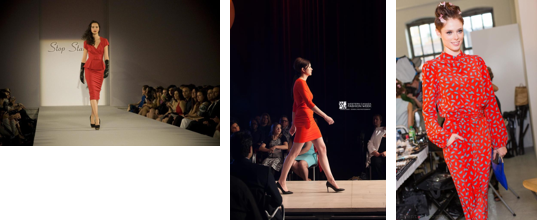

1 위 image_0012|2 위 image_0006|3 위 image_0065

[1 위] ID:image_0091
[Distance: 0.7611]
 Path: c:\workspaces\part2\fashionRAG-assistant\fashion_dataset\image_0091.jpg
[2 위] ID:image_0081
[Distance: 0.7674]
 Path: c:\workspaces\part2\fashionRAG-assistant\fashion_dataset\image_0081.jpg
[3 위] ID:image_0019
[Distance: 0.7771]
 Path: c:\workspaces\part2\fashionRAG-assistant\fashion_dataset\image_0019.jpg


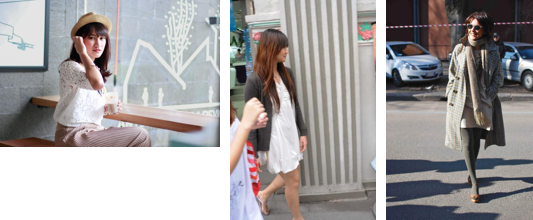

1 위 image_0091|2 위 image_0081|3 위 image_0019


In [19]:
# ============================================================
# [11] 검색 테스트 (OpenAI 없이 CLIP + Chroma 만으로 동작)
# ============================================================
# CLIP 은 주로 영어 데이터로 학습되었으므로 검색어는 '영어'로 넣는 것이 좋습니다.
test_query = "a red dress"
test_query_kor = "빨간 드레스"

results = query_db(image_vdb, test_query, results = 3)
print_results(results)
print()
results2 = query_db(image_vdb, test_query_kor, results = 3)
print_results(results2)

**생각해 보기**: 검색어를 한국어 `"빨간 드레스"` 로 바꿔 [11] 셀을 다시 실행해 보세요. 결과가 어떻게 달라지나요? 왜 그럴까요?  
  
  1. 선정된 이미지 3장이 모두 달랐다.
  2. 같은 의미의 질문인데 겹치는 결과가 없었다.
  3. 한국어 결과 이미지에는 빨간 드레스 결과가 없다.
  4. 실습에서 사용한 openCLIP은 영어로 학습되어 한국어로 질문했을때 오류가 많이 생긴다.

> **나의 메모** : (이 칸을 더블클릭해서 수업 중 알게 된 점을 적어 보세요)
>
> - CLIP은 이미지와 텍스트를 같은 512차원 공간의 벡터로 바꿔주기 때문에, 텍스트로 이미지를 검색할 수 있다.
> - 이미지를 저장하는 순서: 경로 -> ImageLoader가 이미지 배열로 읽음 -> CLIP 이미지 인코더 -> 512차원 벡터 -> img_vdb 폴더에 저장한다.
> - 검색하는 순서: query_texts에 검색어를 넣으면 CLIP 텍스트 인코더가 벡터로 바꾸고, 저장된 이미지 벡터와 거리를 비교해서 가까운 순서로 알려준다.
> - 검색 결과는 리스트 안에 리스트가 들어 있는 구조라서, results["ids"][0]처럼 [0]을 붙여야 첫 번째 검색어의 결과를 꺼낼 수 있다.
> - distance는 작을수록 서로 비슷하다는 뜻이다.

---
# Part 4. LangChain 체인 — 번역 체인 & 비전 체인

### LCEL (LangChain Expression Language)
`|`(파이프) 연산자로 구성요소를 이어 **체인**을 만듭니다. 앞 단계의 출력이 다음 단계의 입력이 됩니다.

```
 {"text": "...", "target_lang": "English"}   ← invoke() 에 넣는 dict
        │  ChatPromptTemplate  : 변수를 채워 메시지 목록 생성
        ▼
 [SystemMessage, HumanMessage]
        │  ChatOpenAI          : OpenAI API 호출
        ▼
 AIMessage(content="...")
        │  StrOutputParser     : content 만 꺼냄
        ▼
 "..." (str)
```

| 구성요소 | 역할 |
|---|---|
| `ChatPromptTemplate.from_messages([...])` | `("system", ...)`, `("user", ...)` 역할별 메시지 템플릿. `{변수}` 자리표시자 사용 |
| `ChatOpenAI(model, temperature)` | OpenAI 채팅 모델. `temperature` 0 = 일관된 답, 높을수록 다양한 답 |
| `StrOutputParser()` | `AIMessage` → 문자열 |
| `chain.invoke(dict)` | 체인 실행 |


In [20]:
# ============================================================
# [12] 번역 체인 (LCEL: 프롬프트 | 모델 | 파서)
# ============================================================
# 원본은 translate() 를 호출할 때마다 모델·프롬프트·체인을 새로 만들었습니다.
# -> 체인을 '한 번만' 만들고, 목표 언어(target_lang)도 프롬프트 변수로 받아 재사용합니다.

# temperature=0.0 : 무작위성 최소화 -> 번역처럼 '정답에 가까운 출력'이 필요할 때 사용
translation_m = ChatOpenAI(model= TRANSLATION_MODEL, temperature= 0.0)

# ChatPromptTemplate.from_messages : (역할, 내용) 튜플 리스트로 대화형 프롬프트 생성
#   {target_lang}, {text} 는 invoke 할 때 채워지는 '자리표시자(변수)'
translation_p =ChatPromptTemplate.from_messages([
    ("system", "You are a professional translator. "
               "Translate the following text to {target_lang}. "
               "Keep markdown formatting. Output only the translation."),
    ("user", "{text}"),
])



# | (파이프) 연산자로 구성요소를 연결 = LCEL(LangChain Expression Language)
#   입력 dict -> 프롬프트(메시지 목록) -> 모델(AIMessage) -> 파서(str)
translation_chain = translation_p | translation_m | StrOutputParser()




def translate(text, target_lang):
    """text 를 target_lang(예: 'English', 'Korean')으로 번역한 문자열을 반환합니다."""
    return translation_chain.invoke({"text":text, "target_lang": target_lang})


# 동작 확인
print(translate("데이트할 때 입을 빨간 원피스", "English"))

Red dress to wear on a date


### 비전 모델에 이미지를 보내는 방법

비전 모델(gpt-4o, gpt-4o-mini)은 user 메시지에 **콘텐츠 블록 리스트**를 받습니다.
```python
[
  {"type": "text",      "text": "질문 ..."},
  {"type": "image_url", "image_url": {"url": "https://... 또는 data:image/jpeg;base64,...."}},
]
```

### base64 와 data URL
- 이미지 파일은 **바이너리(0과 1)** 라서 JSON 텍스트에 바로 넣을 수 없습니다.
- **base64** 는 바이너리를 `A-Z a-z 0-9 + /` 64개 문자로 표현하는 인코딩입니다 (용량은 약 1.33배로 늘어남).
- **data URL** = `data:<MIME 타입>;base64,<base64 문자열>` → 파일을 인터넷에 올리지 않고 URL 자리에 직접 넣을 수 있습니다.
- MIME 타입은 실제 파일 형식과 맞춰야 합니다 (`.jpg` → `image/jpeg`, `.png` → `image/png`).

```
 image_0123.jpg (bytes) ─b64encode─▶ b'/9j/4AAQSk...' ─decode─▶ '/9j/4AAQSk...' (str)
                                                              ─▶ 'data:image/jpeg;base64,/9j/4AAQSk...'
```


In [21]:
# ============================================================
# [13] 비전(멀티모달) 체인: 텍스트 + 이미지 2장을 함께 LLM 에 전달
# ============================================================

def setup_vision_chain():
    """패션 스타일링 조언을 생성하는 '프롬프트 | 비전모델 | 파서' 체인을 반환합니다."""
    # gpt-4o / gpt-4o-mini 는 이미지를 입력으로 이해하는 멀티모달 모델
    vision_model = ChatOpenAI(model=VISION_MODEL, temperature=0.0)
    parser = StrOutputParser()

    # system: 모델의 역할·말투 지정
    #  (해석) 당신은 유용한 패션 및 스타일링 보조자입니다. 제공된 이미지의 특정 부분을 직접 언급하며
    #         이미지 컨텍스트를 사용해 질문에 답하세요. 대화하듯 답하고 목록은 너무 많이 쓰지 마세요.
    #         강조와 구조화를 위해 마크다운을 사용하세요.
    #
    # user: '콘텐츠 블록 리스트' 형식 -> 텍스트 블록 1개 + 이미지 블록 2개
    #   이미지 블록의 url 에 data URL(= data:<MIME>;base64,<데이터>)을 넣으면
    #   이미지 파일을 인터넷에 올리지 않고도 모델에 직접 전달할 수 있음
    #   [원본 수정] PNG 파일인데 'image/jpeg' 로 고정 -> 실제 파일 형식(MIME)을 변수로 전달
    image_prompt = ChatPromptTemplate.from_messages([
        ("system",
         "You are a helpful fashion and styling assistant. "
         "Answer the user's question using the given image context with direct references "
         "to parts of the images provided. Maintain a more conversational tone, "
         "don't make too many lists. Use markdown formatting for highlights, emphasis, and structure."),
        ("user", [
            {"type": "text", "text": "What are some ideas for styling {user_query}"},
            {"type": "image_url", "image_url": {"url": "data:{image_mime_1};base64,{image_data_1}"}},
            {"type": "image_url", "image_url": {"url": "data:{image_mime_2};base64,{image_data_2}"}},
        ]),
    ])
    # 프롬프트 -> 모델 -> 문자열 파서 를 하나의 체인으로 연결해 반환
    return image_prompt | vision_model | parser


def encode_image(path):
    """이미지 파일을 읽어 base64 문자열로 변환합니다.
    바이너리(bytes) --b64encode--> base64 bytes --decode('utf-8')--> 일반 문자열(str)"""
    # 'rb' = 바이너리 읽기 모드
    with open(path, "rb") as f:
        return base64.b64encode(f.read()).decode("utf-8")       


def format_prompt_inputs(data, user_query):
    """검색 결과(data)와 질문으로 비전 프롬프트에 넣을 입력 dict 를 만듭니다.

    반환 예시: {'user_query': '...', 'image_data_1': '/9j/4AAQ...', 'image_mime_1': 'image/jpeg', ...}
    """
    uris = data["uris"][0]              # 첫 번째 검색어의 결과 경로 목록
    
    # 원본 코드는 결과가 2개 미만이면 IndexError 로 중단됨 -> 이해하기 쉬운 메시지로 안내
    if len(uris) < 2:
        raise ValueError(f"이미지가 최소 2장이 필요합니다. 검색결과 {len(uris)}장")
    inputs = {"user_query": user_query}
   
    # 상위 2장만 사용 (n = 1, 2)
    for n, path in enumerate(uris[:2], start =1):
        inputs[f"image_data_{n}"] = encode_image(path)
        inputs[f"image_mime_{n}"] = guess_mime(path)
    return inputs
   


vision_chain = setup_vision_chain()
print("비전 체인 준비 완료")

비전 체인 준비 완료


> **나의 메모** : (이 칸을 더블클릭해서 수업 중 알게 된 점을 적어 보세요)
>
> - 번역 체인은 한 번만 만들어 두고 translate()에서 계속 재사용한다. 목표 언어는 {target_lang} 변수로 받아서 영어/한국어 둘 다 쓸 수 있다.
> - ChatPromptTemplate.from_messages는 (역할, 내용) 튜플 리스트로 만든다. 내용 안의 {변수}는 자리표시자이고, invoke 할 때 dict로 채운다.
> - invoke에 넣는 dict의 키 이름은 프롬프트의 {변수} 이름과 똑같아야 한다. ({"text": ..., "target_lang": ...})
> - 비전 모델은 user 메시지를 콘텐츠 블록 리스트로 받는다.
> - encode_image 순서: open(path, "rb")로 바이너리를 읽음 -> b64encode -> decode("utf-8")로 문자열 변환
> - MIME 타입은 실제 파일 형식과 맞춰야 해서 guess_mime(path)로 확장자를 보고 image/png 또는 image/jpeg를 정한다.
> - format_prompt_inputs에서는 enumerate(uris[:2], start=1)로 image_data 들었다. 검색 결과가 2장보다 적으면 ValueError로 알려준다.

---
# Part 5. 전체 파이프라인 조립

지금까지 만든 부품을 RAG 순서대로 연결합니다.

| 단계 | 함수 | RAG 역할 |
|---|---|---|
| ① 질문 번역 | `translate(query_ko, "English")` | 전처리 |
| ② 이미지 검색 | `query_db(image_vdb, query_en)` | **R**etrieval |
| ③ 프롬프트 입력 구성 | `format_prompt_inputs(results, query_en)` | **A**ugmentation |
| ④ 답변 생성 | `vision_chain.invoke(prompt_input)` | **G**eneration |
| ⑤ 답변 번역 | `translate(response_en, "Korean")` | 후처리 |


In [22]:
# ============================================================
# [14] 전체 파이프라인: 한국어 질문 -> 번역 -> 검색 -> 비전 LLM -> 번역 -> 출력
# ============================================================

def ask_fashion_rag(query_ko, n_results=N_RESULTS, show=True):
    """한국어 질문 하나를 받아 FashionRAG 전체 과정을 실행하고 결과 dict 를 반환합니다."""
    # ① 한국어 질문 -> 영어 (CLIP 검색 품질과 LLM 이해도를 높이기 위해)
    query_en = translate(query_ko, "English")

    # ② CLIP 임베딩 기반 이미지 검색 (Retrieval)
    results = query_db(image_vdb, query_en, results=n_results)

    # ③ 검색된 이미지 + 질문을 프롬프트 입력으로 변환 (Augmentation)
    prompt_input = format_prompt_inputs(results, query_en)

    # ④ 비전 모델이 이미지를 보고 스타일링 조언 생성 (Generation)
    response_en = vision_chain.invoke(prompt_input)

    # ⑤ 영어 답변 -> 한국어
    response_ko = translate(response_en, "Korean")

    if show:
        print("번역된 검색어:", query_en)
        print("\n[검색된 이미지]")
        print_results(results)
        print("\n[FashionRAG 의 응답]")
        display(Markdown(response_ko))   # 마크다운(굵게, 제목 등)을 렌더링해서 출력

    return {"query_en": query_en, "results": results,
            "response_en": response_en, "response_ko": response_ko}

번역된 검색어: Let me know how to style a trench coat that's good for winter.

[검색된 이미지]
[1 위] ID:image_0019
[Distance: 0.7102]
 Path: c:\workspaces\part2\fashionRAG-assistant\fashion_dataset\image_0019.jpg
[2 위] ID:image_0074
[Distance: 0.7406]
 Path: c:\workspaces\part2\fashionRAG-assistant\fashion_dataset\image_0074.jpg


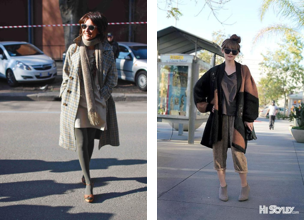

1 위 image_0019|2 위 image_0074

[FashionRAG 의 응답]


겨울철 트렌치 코트를 스타일링하는 것은 세련되면서도 기능적일 수 있습니다! 제공하신 이미지를 바탕으로 몇 가지 아이디어를 소개합니다:

### 1. **따뜻함을 위한 레이어링**
   - **베이스 레이어**: 아늑한 니트 스웨터나 터틀넥으로 시작하세요. 첫 번째 이미지에서 모델은 트렌치 코트와 잘 어울리는 밝은 색상의 스웨터를 입고 있습니다.
   - **타이츠 또는 레깅스**: 두꺼운 타이츠나 레깅스를 선택하여 다리를 따뜻하게 유지하세요. 모델은 올리브 그린 타이츠와 트렌치 코트를 매치하여 색상의 멋진 포인트를 추가했습니다.

### 2. **액세서리**
   - **스카프**: 두꺼운 니트 스카프는 따뜻함과 스타일을 모두 더할 수 있습니다. 첫 번째 이미지의 모델은 질감과 대비를 더하는 멋진 스카프를 착용하고 있습니다.
   - **선글라스**: 오버사이즈 선글라스는 스타일을 유지하면서 룩을 한층 높여줄 수 있습니다. 두 이미지 모두에서 볼 수 있습니다.

### 3. **신발 선택**
   - **부츠**: 무릎 높이 또는 발목 부츠는 겨울에 완벽합니다. 발을 따뜻하게 유지할 뿐만 아니라 스타일리시한 엣지를 더해줍니다.
   - **힐**: 좀 더 드레시하게 연출하고 싶다면, 첫 번째 이미지에서 볼 수 있는 발목 힐 부츠를 선택하세요.

### 4. **색상 조화**
   - **중립 톤**: 클래식한 룩을 위해 중립적인 팔레트를 유지하거나 올리브나 녹슨 색상과 같은 자연적인 색상을 섞어 겨울에 적합하게 연출하세요.
   - **패턴**: 트렌치 코트에 패턴이 있다면(첫 번째 이미지의 체크무늬처럼), 나머지 의상은 더 차분하게 유지하여 코트가 돋보이게 하세요.

### 5. **아우터웨어 레이어링**
   - **트렌치 아래**: 추가적인 따뜻함을 위해 몸에 맞는 재킷이나 긴 카디건을 아래에 입는 것을 고려하세요. 두 번째 이미지는 트렌치 위에 레이어링할 수 있는 더 편안한 아우터 레이어를 보여줍니다.

### 6. **마무리 터치**
   - **가방**: 구조적인 핸드백은 룩에 세련됨을 더할 수 있습니다. 의상의 색상과 잘 어울리는 것을 선택하세요.
   - **주얼리**: 간단하고 우아한 주얼리는 의상을 압도하지 않으면서 전체적인 외모를 향상시킬 수 있습니다.

이 요소들을 조합하여 트렌치 코트로 스타일리시하고 따뜻한 겨울 룩을 만들어보세요!

In [23]:
# ============================================================
# [15] FashionRAG 실행해 보기
# ============================================================
answer = ask_fashion_rag("겨울에 입기 좋은 트렌치코트 스타일링 알려줘")

다른 질문으로도 바꿔 실행해 보세요. 예) `"하객룩으로 어울리는 원피스"`, `"캐주얼한 데님 재킷 코디"`, `"여름 휴가지에서 입을 린넨 셔츠"`

FashionRAG 가 여러분의 서비스를 위해 준비되었습니다!
번역된 검색어: Autumn feeling

[검색된 이미지]
[1 위] ID:image_0068
[Distance: 0.7340]
 Path: c:\workspaces\part2\fashionRAG-assistant\fashion_dataset\image_0068.jpg
[2 위] ID:image_0032
[Distance: 0.7762]
 Path: c:\workspaces\part2\fashionRAG-assistant\fashion_dataset\image_0032.jpg


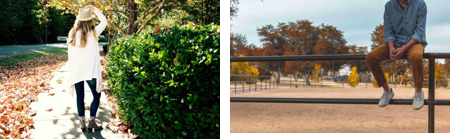

1 위 image_0068|2 위 image_0032

[FashionRAG 의 응답]


아늑한 가을 분위기를 위한 스타일링은 정말 재미있을 수 있어요! 여러분이 공유한 이미지에서 영감을 받은 몇 가지 아이디어를 소개합니다:

### 첫 번째 이미지의 여성에게:
1. **레이어링**: 긴 흐르는 카디건은 가을에 완벽합니다. 그 아래에 핏된 터틀넥을 매치하면 따뜻함과 스타일을 더할 수 있습니다.
2. **액세서리**: 모자는 세련된 느낌을 더해줍니다. 버너 오렌지나 머스타드 같은 따뜻한 색조의 스카프를 추가하여 가을 느낌을 강조해보세요.
3. **신발**: 앵클 부츠는 훌륭한 선택입니다! 가을 단풍과 잘 어울리는 자연적인 색조의 스웨이드나 가죽을 선택하세요.
4. **데님**: 어두운 청바지는 다재다능합니다. 하이웨이스트 스타일이나 복고풍의 코듀로이도 시도해보세요.

### 두 번째 이미지의 남성에게:
1. **캐주얼 레이어**: 데님 셔츠는 클래식한 선택입니다. 가벼운 스웨터나 플란넬 셔츠와 레이어링하여 추가적인 따뜻함을 더할 수 있습니다.
2. **바지**: 갈색 바지는 훌륭한 가을 색상입니다. 올리브나 녹슨 색조의 치노로 바꾸어 계절에 맞는 업데이트를 고려해보세요.
3. **신발**: 스니커즈는 캐주얼한 룩에 잘 어울리지만, 더 세련된 느낌을 원한다면 가죽으로 된 더즌 부츠나 로퍼를 시도해보세요.
4. **액세서리**: 비니나 스카프는 따뜻함과 스타일을 모두 더할 수 있으며, 특히 의상과 보완되는 색상으로 선택하세요.

### 일반 팁:
- **색상 팔레트**: 갈색, 오렌지, 깊은 녹색과 같은 따뜻하고 자연적인 색조를 활용하여 계절을 반영하세요.
- **텍스처**: 니트, 스웨이드, 데님과 같은 다양한 텍스처를 포함시켜 의상에 깊이를 더하세요.
- **레이어링**: 가을은 레이어링의 계절이므로 스타일과 편안함을 위해 다양한 아이템을 믹스 앤 매치하는 것을 주저하지 마세요.

이 아이디어들로 가을 시즌을 스타일리시하게 맞이할 준비가 되실 거예요! 🍂

FashionRAG 를 종료합니다.


In [24]:
# ============================================================
# [16] (선택) 대화형 모드 - 원본 스크립트의 while 루프
# ============================================================
# 노트북에서 input() 무한 루프를 바로 돌리면 '셀 전체 실행' 시 멈춘 것처럼 보이므로
# 기본값은 False 입니다. 직접 대화해 보고 싶을 때만 True 로 바꿔 실행하세요.
RUN_INTERACTIVE = True

if RUN_INTERACTIVE:
    print("FashionRAG 가 여러분의 서비스를 위해 준비되었습니다!")
    while True:
        query_ko = input("\n스타일 질문을 입력하세요 (종료: quit): ").strip()
        if query_ko.lower() in ("quit", "exit", "q", "종료"):
            print("FashionRAG 를 종료합니다.")
            break
        if not query_ko:          # 빈 입력은 무시
            continue
        try:
            ask_fashion_rag(query_ko)
        except Exception as e:    # API 오류 등이 나도 루프가 죽지 않도록 처리
            print("오류가 발생했습니다:", e)
else:
    print("대화형 모드를 사용하려면 RUN_INTERACTIVE = True 로 바꾸고 다시 실행하세요.")

> **나의 메모** : (이 칸을 더블클릭해서 수업 중 알게 된 점을 적어 보세요)
>
> - 함수에서 template 변수로 다 처리해서 자동화 함.

---
# Part 6. ✏️ 실습 문제



### 실습 1. 검색 개수 바꾸기
`"a black leather jacket"` 과 가장 비슷한 사진 **4장**을 찾아 출력하세요.


[1 위] ID:image_0099
[Distance: 0.6913]
 Path: c:\workspaces\part2\fashionRAG-assistant\fashion_dataset\image_0099.jpg
[2 위] ID:image_0005
[Distance: 0.7403]
 Path: c:\workspaces\part2\fashionRAG-assistant\fashion_dataset\image_0005.jpg
[3 위] ID:image_0080
[Distance: 0.7484]
 Path: c:\workspaces\part2\fashionRAG-assistant\fashion_dataset\image_0080.jpg
[4 위] ID:image_0037
[Distance: 0.7541]
 Path: c:\workspaces\part2\fashionRAG-assistant\fashion_dataset\image_0037.jpg


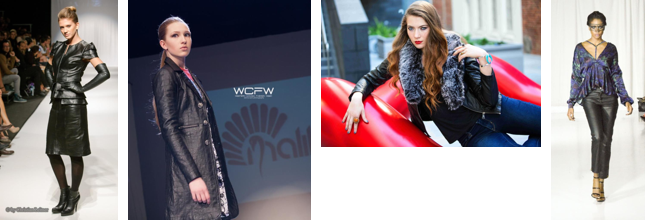

1 위 image_0099|2 위 image_0005|3 위 image_0080|4 위 image_0037


In [25]:
# [실습 1] "a black leather jacket" 과 비슷한 이미지 4장을 검색하고 출력해 보세요.
# 힌트: query_db(컬렉션, 검색어, results=개수) / print_results(결과)

ex1_results = query_db(image_vdb, "a black leather jacket", results=4)
print_results(ex1_results)

### 실습 2. 이미지로 이미지 검색 (Image → Image)
CLIP 은 이미지와 텍스트가 같은 공간에 있으므로, **사진을 검색어로** 넣어 비슷한 사진을 찾을 수도 있습니다. `query_uris` 를 사용해 보세요.

[1 위] ID:image_0001
[Distance: 0.0000]
 Path: c:\workspaces\part2\fashionRAG-assistant\fashion_dataset\image_0001.jpg
[2 위] ID:image_0016
[Distance: 0.3097]
 Path: c:\workspaces\part2\fashionRAG-assistant\fashion_dataset\image_0016.jpg
[3 위] ID:image_0093
[Distance: 0.3552]
 Path: c:\workspaces\part2\fashionRAG-assistant\fashion_dataset\image_0093.jpg


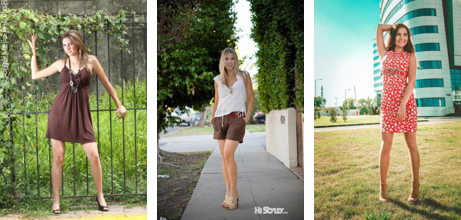

1 위 image_0001|2 위 image_0016|3 위 image_0093


In [29]:
# [실습 2] 이미지로 이미지 검색하기 (Image -> Image)
# CLIP 은 이미지와 텍스트가 같은 벡터 공간에 있으므로 '이미지'로도 검색할 수 있습니다.
# Chroma 의 query() 는 query_texts 대신 query_uris(이미지 경로 리스트)를 받을 수 있습니다.
# 첫 번째 이미지를 검색어로 사용


query_path = [os.path.join(DATASET_FOLDER, image_files[0])]   # 이미지 경로 '리스트'

ex2_results = image_vdb.query(
    query_uris = query_path,
    n_results = 3,
    include = ["uris", "distances"],
)



print_results(ex2_results)
# 질문: 1위 결과는 무엇이고, distance 는 얼마인가요? 왜 그럴까요?

### 실습 3. 페르소나 바꾸기
system 프롬프트만 바꿔서 **'가성비 스타일리스트'** 챗봇을 만들어 보세요.

In [31]:
# [실습 3] 페르소나 바꾸기: '예산 친화적(가성비) 스타일리스트' 체인 만들기
# 아래 system 메시지를 '저렴한 아이템으로 비슷한 느낌을 내는 방법을 알려주는 스타일리스트'로 바꿔 보세요.
budget_prompt = ChatPromptTemplate.from_messages([
    ("system",
     "You are a helpful budget-friendly fashion and styling assistant. "
     "Using the given image context with direct references to parts of the images provided, "
     "show the user how to recreate a similar look with affordable items. "
     "Suggest low-cost alternatives, and mention where to save money. "
     "Maintain a conversational tone, don't make too many lists. "
     "Use markdown formatting for highlights, emphasis, and structure."),
    ("user", [
        {"type": "text", "text": "What are some ideas for styling {user_query}"},
        {"type": "image_url", "image_url": {"url": "data:{image_mime_1};base64,{image_data_1}"}},
        {"type": "image_url", "image_url": {"url": "data:{image_mime_2};base64,{image_data_2}"}},
    ]),
])
budget_chain = budget_prompt | ChatOpenAI(model=VISION_MODEL) | StrOutputParser()   # TODO: budget_prompt | 모델 | 파서 로 체인을 완성하세요

q = translate("출근룩으로 입을 니트", "English")
inputs = format_prompt_inputs(query_db(image_vdb, q), q)
display(Markdown(translate(budget_chain.invoke(inputs), "Korean")))

직장에서 니트웨어를 스타일링하는 것은 세련되면서도 편안할 수 있습니다! 공유하신 이미지를 바탕으로 몇 가지 아이디어를 제안합니다.

### **포인트 코트와 레이어링**
첫 번째 이미지에서는 니트 탑이 맞춤형 코트와 아름답게 조화를 이루는 모습을 볼 수 있습니다. 비슷한 룩을 재현하려면:

- **청키 니트 스웨터 선택:** 중립적인 색상의 청키 니트를 선택하세요. 아늑하면서도 세련됩니다.
- **구조적인 외투 추가:** 스웨터 위에 입을 수 있는 저렴한 맞춤형 블레이저나 긴 가디건을 찾아보세요. 이는 즉시 당신의 의상을 격상시키면서도 전문적인 느낌을 유지합니다.
- **하의도 중요:** 맞춤형 바지나 펜슬 스커트와 매치하여 직장에 적합한 분위기를 유지하세요.

### **미디 스커트와 니트 탑**
두 번째 이미지에서는 스타일리시한 니트 탑과 세련된 미디 스커트의 조합을 보여줍니다:

- **핏이 좋은 니트 탑 선택:** 간단하고 핏이 좋은 니트 탑이나 터틀넥이 룩을 간결하게 유지할 수 있습니다.
- **패턴으로 놀기:** 단색 탑은 대담한 패턴이나 스트라이프 미디 스커트와 아름답게 어울립니다. 이는 너무 캐주얼하지 않으면서도 재미있는 요소를 추가합니다.
- **신발:** 이미지와 같은 무릎 높이의 부츠는 세련미를 더합니다. 비용을 절약하고 싶다면 중고 가게나 세일에서 비슷한 스타일을 찾아보세요.

### **강화할 액세서리**
- **미니멀한 주얼리:** 액세서리는 가볍게 유지하세요. 간단한 스터드 귀걸이나 섬세한 목걸이가 의상을 과하지 않게 강조할 수 있습니다.
- **구조적인 가방:** 구조적인 토트백이나 핸드백은 어떤 니트웨어 룩에도 전문성을 더합니다. 계절을 넘나들 수 있는 중립색이나 깊은 색상을 선택하세요.

### **색상 조화**
색상을 두려워하지 마세요! 첫 번째 룩은 단색으로 유지되지만, 니트웨어와 하의의 톤을 혼합하면 시각적으로 매력적인 대비를 만들 수 있습니다. 단, 색상이 유사한 팔레트 내에서 유지되도록 하여 일관된 룩을 만들어야 합니다.

### **마지막 팁**
- **편안함과 스타일의 조화:** 너무 부피가 크지 않으면서도 따뜻함을 제공하는 원단을 선택하세요.
- **텍스처 혼합:** 니트웨어와 다양한 텍스처(실크, 면, 가죽 등)를 결합하면 의상이 돋보이면서도 세련된 느낌을 줄 수 있습니다.

이 요소들을 결합하면 니트웨어의 편안함을 유지하면서도 스타일리시하고 직장에 적합한 의상을 만들 수 있습니다! 스타일링을 즐기세요! 😊

### 실습 4. 거리 임계값 필터
너무 동떨어진 사진은 LLM 에 보내지 않는 것이 좋습니다. distance 가 기준 이하인 결과만 남기는 함수를 완성하세요.

In [32]:
# [실습 4] 거리 임계값(threshold) 필터
# 검색 결과 중 distance 가 기준값 '이하'(=충분히 비슷한)인 결과만 남기는 함수를 완성하세요.
def filter_by_distance(results, max_distance):
    kept = []
    for rid, uri, dist in zip(results["ids"][0], results["uris"][0], results["distances"][0]):
        if dist <= max_distance:            # TODO: 조건을 작성하세요
            kept.append((rid, uri, dist))
    return kept

r = query_db(image_vdb, "a person wearing sunglasses", results=5)
print("전체 거리:", [round(d, 3) for d in r["distances"][0]])
print("필터 결과:", filter_by_distance(r, max_distance=0.79))

전체 거리: [0.769, 0.78, 0.796, 0.802, 0.804]
필터 결과: [('image_0077', 'c:\\workspaces\\part2\\fashionRAG-assistant\\fashion_dataset\\image_0077.jpg', 0.7689130902290344), ('image_0003', 'c:\\workspaces\\part2\\fashionRAG-assistant\\fashion_dataset\\image_0003.jpg', 0.7795319557189941)]


---
# 확인 퀴즈

1. CLIP 으로 **텍스트로 이미지를 검색**할 수 있는 이유는 무엇인가요?
2. Chroma 에서 `distance` 값이 **작을수록** 의미하는 것은?
3. 이미지를 OpenAI 비전 모델에 보낼 때 **base64 로 인코딩**하는 이유는?
4. `load_dataset(..., streaming=True)` 를 쓰면 무엇이 좋아지나요?
5. 원본 스크립트를 노트북으로 옮겼을 때 `__file__` 에서 에러가 나는 이유는?
6. FashionRAG 에서 번역을 두 번(질문, 답변) 하는 이유는?
7. LCEL 에서 `prompt | model | parser` 각 단계의 **출력 타입**을 순서대로 적어 보세요.

(답을 아래 메모 칸에 적어 보세요)


> **나의 메모** : (이 칸을 더블클릭해서 수업 중 알게 된 점을 적어 보세요)
>
> 1. CLIP은 텍스트 인코더와 이미지 인코더가 같은 512차원 벡터 공간을 쓰도록 학습되어 있다. 그래서 텍스트 벡터와 가까운 이미지 벡터를 찾으면 텍스트로 이미지를 검색할 수 있다.
> 2. distance가 작을수록 두 벡터가 가깝다는 뜻이고, 곧 서로 의미가 비슷하다는 뜻이다.
> 3. 이미지 파일은 바이너리라서 JSON 텍스트에 바로 넣을 수 없다.
> 4. 전체 데이터셋을 디스크에 다 받지 않고, 필요한 만큼(num_images)만 실시간으로 읽어 올 수 있다.
> 5. 주피터 노트북에는 `__file__` 변수가 없어서 NameError가 난다. `__file__`은 .py 파일에서만 동작하기 때문에, 노트북에서는 os.getcwd()로 현재 작업 폴더를 기준으로 잡는다.
> 6. 질문 번역: CLIP은 주로 영어로 학습되어서 영어로 검색해야 정확하고, 비전 모델도 영어 질문을 더 잘 이해한다. 답변 번역: 사용자는 한국어로 읽어야 하므로 영어 답변을 다시 한국어로 바꿔 준다.
> 7. prompt는 메시지 목록(ChatPromptValue), model은 AIMessage, parser는 문자열(str)이다.

---
# 정리

| 오늘 배운 것 | 핵심 한 줄 |
|---|---|
| 멀티모달 RAG | 이미지를 검색해서 비전 LLM 의 근거로 사용 |
| CLIP | 텍스트와 이미지를 같은 벡터 공간에 → 텍스트로 이미지 검색 |
| Chroma | `embedding_function` + `data_loader` 로 경로만 넣으면 임베딩·저장 자동 |
| LCEL | `prompt | model | parser`, `invoke(dict)` |
| 비전 입력 | `{"type": "image_url", "image_url": {"url": "data:<MIME>;base64,..."}}` |

### 더 나아가기
- **다국어 CLIP**(예: `xlm-roberta-base-ViT-B-32`)을 쓰면 번역 없이 한국어로 바로 검색 가능
- **메타데이터 필터**: Fashionpedia 의 의류 카테고리를 `metadatas` 로 저장해 `where={"category": "dress"}` 로 필터 검색
- **대화 기억**: `RunnableWithMessageHistory` 로 이전 질문 맥락 유지
- **웹 UI**: Gradio / Streamlit 으로 `ask_fashion_rag()` 를 감싸 웹 데모 만들기
